In [1]:
import pandas as pd
import numpy as np

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
fake_news = pd.read_csv("../data/Fake.csv")
real_news = pd.read_csv("../data/True.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
fake_news.head()

,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"


In [4]:
real_news.head()

,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"


In [5]:
print("Fake News Shape:", fake_news.shape)
print("Real News Shape:", real_news.shape)

print("\nFake News Columns:")
print(fake_news.columns)

print("\nReal News Columns:")
print(real_news.columns)

Fake News Shape: (23481, 4)
Real News Shape: (21417, 4)

Fake News Columns:
Index(['title', 'text', 'subject', 'date'], dtype='str')

Real News Columns:
Index(['title', 'text', 'subject', 'date'], dtype='str')


In [6]:
# Add labels to datasets
fake_news["label"] = 0
real_news["label"] = 1

# Combine fake and real news
news_data = pd.concat([fake_news, real_news], axis=0)

# Shuffle dataset
news_data = news_data.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

# Display dataset
news_data.head()

,title,text,subject,date,label
0,Ben Stein Calls Out 9th Circuit Court: Committ...,"21st Century Wire says Ben Stein, reputable pr...",US_News,"February 13, 2017",0
1,Trump drops Steve Bannon from National Securit...,WASHINGTON (Reuters) - U.S. President Donald T...,politicsNews,"April 5, 2017",1
2,Puerto Rico expects U.S. to lift Jones Act shi...,(Reuters) - Puerto Rico Governor Ricardo Rosse...,politicsNews,"September 27, 2017",1
3,OOPS: Trump Just Accidentally Confirmed He Le...,"On Monday, Donald Trump once again embarrassed...",News,"May 22, 2017",0
4,Donald Trump heads for Scotland to reopen a go...,"GLASGOW, Scotland (Reuters) - Most U.S. presid...",politicsNews,"June 24, 2016",1


In [7]:
print("Total News:", len(news_data))

print("\nLabel Distribution:")
print(news_data["label"].value_counts())

print("\nDataset Shape:")
print(news_data.shape)

print("\nMissing Values:")
print(news_data.isnull().sum())

Total News: 44898

Label Distribution:
label
0    23481
1    21417
Name: count, dtype: int64

Dataset Shape:
(44898, 5)

Missing Values:
title      0
text       0
subject    0
date       0
label      0
dtype: int64


In [8]:
news_data.to_csv(
    "../data/news_dataset.csv",
    index=False
)

print("Combined dataset saved successfully!")

Combined dataset saved successfully!


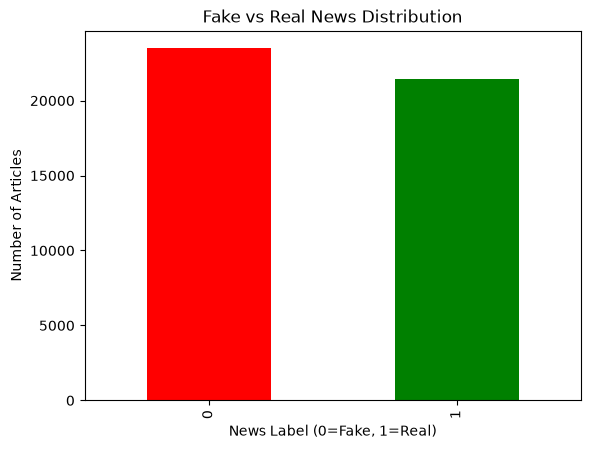

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count real and fake news
news_data["label"].value_counts().plot(
    kind="bar",
    color=["red", "green"]
)

plt.title("Fake vs Real News Distribution")
plt.xlabel("News Label (0=Fake, 1=Real)")
plt.ylabel("Number of Articles")

plt.show()

In [11]:
# Calculate article word count
news_data["word_count"] = news_data["text"].apply(
    lambda x: len(str(x).split())
)

# Display first 5 records
news_data[["text", "word_count", "label"]].head()

,text,word_count,label
0,"21st Century Wire says Ben Stein, reputable pr...",171,0
1,WASHINGTON (Reuters) - U.S. President Donald T...,771,1
2,(Reuters) - Puerto Rico Governor Ricardo Rosse...,304,1
3,"On Monday, Donald Trump once again embarrassed...",183,0
4,"GLASGOW, Scotland (Reuters) - Most U.S. presid...",529,1


In [12]:
print("Average Fake News Word Count:")
print(news_data[news_data["label"] == 0]["word_count"].mean())

print("\nAverage Real News Word Count:")
print(news_data[news_data["label"] == 1]["word_count"].mean())

Average Fake News Word Count:
423.1979046888974

Average Real News Word Count:
385.6400989867862


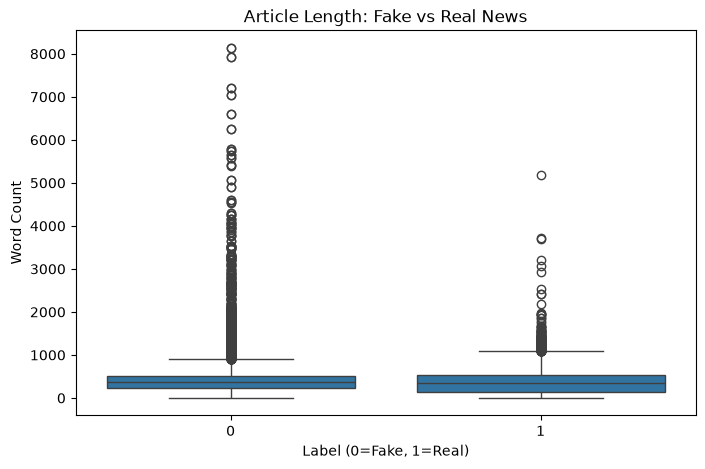

In [13]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=news_data,
    x="label",
    y="word_count"
)

plt.title("Article Length: Fake vs Real News")
plt.xlabel("Label (0=Fake, 1=Real)")
plt.ylabel("Word Count")

plt.show()

In [14]:
import re

def clean_text(text):
    text = str(text)

    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Remove special characters
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [15]:
news_data["text_clean"] = news_data["text"].apply(clean_text)

news_data[["text", "text_clean"]].head()

,text,text_clean
0,"21st Century Wire says Ben Stein, reputable pr...",st century wire says ben stein reputable profe...
1,WASHINGTON (Reuters) - U.S. President Donald T...,washington reuters u s president donald trump ...
2,(Reuters) - Puerto Rico Governor Ricardo Rosse...,reuters puerto rico governor ricardo rossello ...
3,"On Monday, Donald Trump once again embarrassed...",on monday donald trump once again embarrassed ...
4,"GLASGOW, Scotland (Reuters) - Most U.S. presid...",glasgow scotland reuters most u s presidential...


In [16]:
print("Original Text:")
print(news_data["text"].iloc[0])

print("\nCleaned Text:")
print(news_data["text_clean"].iloc[0])

Original Text:
21st Century Wire says Ben Stein, reputable professor from, Pepperdine University (also of some Hollywood fame appearing in TV shows and films such as Ferris Bueller s Day Off) made some provocative statements on Judge Jeanine Pirro s show recently. While discussing the halt that was imposed on President Trump s Executive Order on travel. Stein referred to the judgement by the 9th Circuit Court in Washington state as a  Coup d tat against the executive branch and against the constitution.  Stein went on to call the Judges in Seattle  political puppets  and the judiciary  political pawns. Watch the interview below for the complete statements and note the stark contrast to the rhetoric of the leftist media and pundits who neglect to note that no court has ever blocked any Presidential orders in immigration in the past or discuss the legal efficacy of the halt or the actual text of the Executive Order.READ MORE TRUMP NEWS AT: 21st Century Wire Trump FilesSUPPORT OUR WORK BY

In [17]:
news_data.to_csv(
    "../data/cleaned_news_dataset.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [19]:
from sklearn.feature_extraction.text import TfidfVectorizer

print("TF-IDF imported successfully!")

TF-IDF imported successfully!


In [20]:
tfidf = TfidfVectorizer(
    max_features=5000,
    stop_words="english",
    ngram_range=(1, 2)
)

X = tfidf.fit_transform(news_data["text_clean"])
y = news_data["label"]

print("Feature extraction completed!")
print("X Shape:", X.shape)
print("Y Shape:", y.shape)

Feature extraction completed!
X Shape: (44898, 5000)
Y Shape: (44898,)


In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (35918, 5000)
Testing Data: (8980, 5000)


In [22]:
from sklearn.linear_model import LogisticRegression

print("Logistic Regression imported successfully!")

Logistic Regression imported successfully!


In [23]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [24]:
y_pred = model.predict(X_test)

print("Predictions completed!")
print(y_pred[:10])

Predictions completed!
[1 1 0 1 1 0 1 0 1 1]


In [25]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 98.80846325167037 %


In [26]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.99      0.98      0.99      4696
           1       0.98      0.99      0.99      4284

    accuracy                           0.99      8980
   macro avg       0.99      0.99      0.99      8980
weighted avg       0.99      0.99      0.99      8980



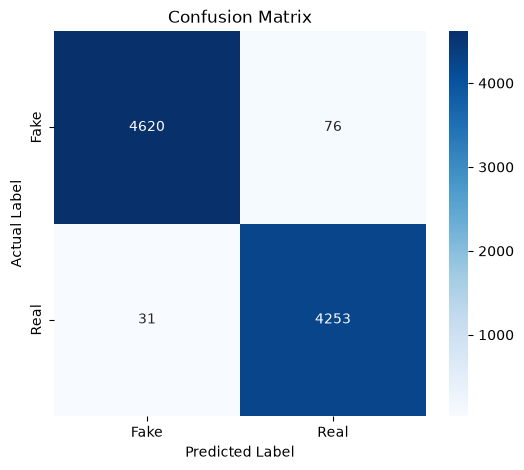

In [27]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fake", "Real"],
    yticklabels=["Fake", "Real"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [28]:
import joblib

joblib.dump(model, "../models/news_model.pkl")
joblib.dump(tfidf, "../models/tfidf_vectorizer.pkl")

print("Model and vectorizer saved successfully!")

Model and vectorizer saved successfully!


In [29]:
def predict_news(news_text):
    # Clean the input text
    cleaned_text = clean_text(news_text)

    # Convert text into TF-IDF features
    vectorized_text = tfidf.transform([cleaned_text])

    # Predict news label
    prediction = model.predict(vectorized_text)[0]

    # Predict probability
    probabilities = model.predict_proba(vectorized_text)[0]

    if prediction == 0:
        result = "LIKELY FAKE NEWS"
        confidence = probabilities[0] * 100
    else:
        result = "LIKELY REAL NEWS"
        confidence = probabilities[1] * 100

    return result, confidence

In [30]:
sample_news = """
Scientists discovered a new technology that improves renewable energy production.
"""

result, confidence = predict_news(sample_news)

print("Prediction:", result)
print("Model Confidence:", round(confidence, 2), "%")

Prediction: LIKELY FAKE NEWS
Model Confidence: 75.11 %


In [31]:
sample_news = """
The government announced a new policy during an official press conference.
"""

result, confidence = predict_news(sample_news)

print("Prediction:", result)
print("Model Confidence:", round(confidence, 2), "%")

Prediction: LIKELY FAKE NEWS
Model Confidence: 95.85 %


In [32]:

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Naive Bayes": MultinomialNB(),
    "Linear SVM": LinearSVC()
}

results = []

for name, model in models.items():

    print("Training:", name)

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0)
    })

print("Model comparison completed!")


Training: Logistic Regression
Training: Naive Bayes
Training: Linear SVM
Model comparison completed!


In [33]:
import pandas as pd

results_df = pd.DataFrame(results)

print(results_df.round(4))

                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression    0.9881     0.9824  0.9928    0.9876
1          Naive Bayes    0.9462     0.9433  0.9440    0.9436
2           Linear SVM    0.9945     0.9930  0.9956    0.9943


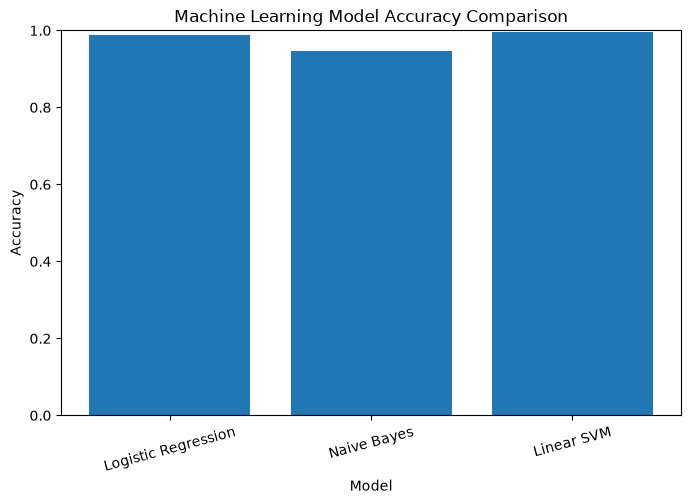

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    results_df["Model"],
    results_df["Accuracy"]
)

plt.title("Machine Learning Model Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy")

plt.ylim(0, 1)
plt.xticks(rotation=15)

plt.show()

In [35]:
results_df.to_csv(
    "../data/model_comparison_results.csv",
    index=False
)

print("Model comparison results saved!")

Model comparison results saved!


In [36]:
print(news_data["label"].value_counts())

label
0    23481
1    21417
Name: count, dtype: int64


In [37]:
import pandas as pd

print(pd.Series(y_pred).value_counts())

0    4651
1    4329
Name: count, dtype: int64


In [38]:
print(news_data[["text", "label"]].head(10))

                                                text  label
0  21st Century Wire says Ben Stein, reputable pr...      0
1  WASHINGTON (Reuters) - U.S. President Donald T...      1
2  (Reuters) - Puerto Rico Governor Ricardo Rosse...      1
3  On Monday, Donald Trump once again embarrassed...      0
4  GLASGOW, Scotland (Reuters) - Most U.S. presid...      1
5  On Wednesday, Democrats took a powerful stance...      0
6  President Trump s rally in FL on Saturday was ...      0
7  He s been Europe s version of the outspoken Te...      0
8  WASHINGTON (Reuters) - The State Department sa...      1
9   (This version of the story corrects the figur...      1


In [39]:
print("Actual labels:")
print(y_test.value_counts())

print("\nPredicted labels:")
print(pd.Series(y_pred).value_counts())

Actual labels:
label
0    4696
1    4284
Name: count, dtype: int64

Predicted labels:
0    4651
1    4329
Name: count, dtype: int64


In [40]:
print(news_data["label"].value_counts())

label
0    23481
1    21417
Name: count, dtype: int64


In [41]:
print("Fake news sample:")
print(news_data[news_data["label"] == 0]["text"].iloc[0])

print("\nReal news sample:")
print(news_data[news_data["label"] == 1]["text"].iloc[0])

Fake news sample:
21st Century Wire says Ben Stein, reputable professor from, Pepperdine University (also of some Hollywood fame appearing in TV shows and films such as Ferris Bueller s Day Off) made some provocative statements on Judge Jeanine Pirro s show recently. While discussing the halt that was imposed on President Trump s Executive Order on travel. Stein referred to the judgement by the 9th Circuit Court in Washington state as a  Coup d tat against the executive branch and against the constitution.  Stein went on to call the Judges in Seattle  political puppets  and the judiciary  political pawns. Watch the interview below for the complete statements and note the stark contrast to the rhetoric of the leftist media and pundits who neglect to note that no court has ever blocked any Presidential orders in immigration in the past or discuss the legal efficacy of the halt or the actual text of the Executive Order.READ MORE TRUMP NEWS AT: 21st Century Wire Trump FilesSUPPORT OUR WORK

In [42]:
from sklearn.metrics import classification_report, confusion_matrix

print(classification_report(
    y_test,
    y_pred,
    target_names=["Fake News", "Real News"]
))

              precision    recall  f1-score   support

   Fake News       0.99      0.98      0.99      4696
   Real News       0.98      0.99      0.99      4284

    accuracy                           0.99      8980
   macro avg       0.99      0.99      0.99      8980
weighted avg       0.99      0.99      0.99      8980



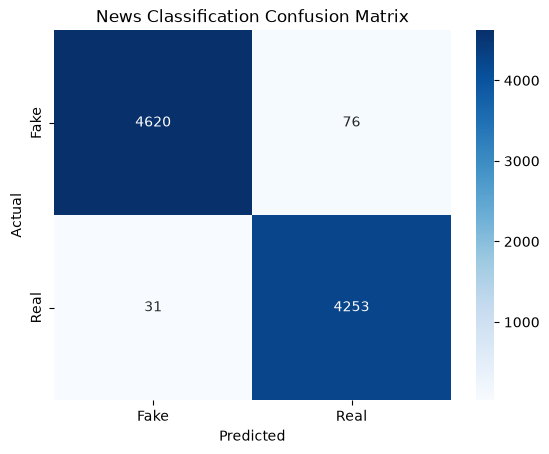

In [43]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fake", "Real"],
    yticklabels=["Fake", "Real"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("News Classification Confusion Matrix")
plt.show()